# UCR-MFG: Experiments and Results on UAVDT
This notebook contains the experimental results of the paper with their outputs: dataset statistics, training curves,
test results (single view and test-time augmentation), the comparison with the plain detector, the breakdown by class,
weather and altitude, the quality of the uncertainty estimates, the TTA selection, sample detections and inference speed.

All numbers are read from the saved result files (`results/`, `checkpoints/*/train_log.jsonl`); sections 8–9 run the
final model live.

## 1. Setup

In [1]:
import os, sys, json, time, inspect, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT)
sys.path.insert(0, ROOT); sys.path.insert(0, os.path.join(ROOT, "scripts"))
import numpy as np, torch, yaml
import matplotlib.pyplot as plt
try:
    from IPython.display import display
except ImportError:
    display = print

def show_table(headers, rows, title=None):
    """Plain-text table (no pandas needed)."""
    cells = [[str(h) for h in headers]] + [[str(v) for v in r] for r in rows]
    w = [max(len(r[i]) for r in cells) for i in range(len(headers))]
    if title:
        print(title)
    for k, r in enumerate(cells):
        print("  ".join(v.rjust(w[i]) if i else v.ljust(w[i]) for i, v in enumerate(r)))
        if k == 0:
            print("  ".join("-" * x for x in w))

device = torch.device("mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu")
print("project root:", ROOT)
print("torch", torch.__version__, "| device:", device)

project root: /Users/rahulmahaseth/Desktop/ucr_mfg
torch 2.15.0 | device: mps


## 2. Dataset: UAVDT

In [2]:
from collections import Counter
from src.data.uavdt import UAVDTDataset
train = UAVDTDataset("dataset/UAVDT-Benchmark-M", "train", (544, 1024), is_train=False, frame_stride=1)
test = UAVDTDataset("dataset/UAVDT-Benchmark-M", "test", (544, 1024), is_train=False, frame_stride=1)
train30 = UAVDTDataset("dataset/UAVDT-Benchmark-M", "train", (544, 1024), is_train=False, frame_stride=30)
eval_idx = list(range(2, len(test), 5))
seqs = lambda d: sorted({s for s, _, _ in d.frames})
show_table(["split", "videos", "frames", "used"], [
    ["train", len(seqs(train)), f"{len(train.frames):,}", f"{len(train30):,} (every 30th frame)"],
    ["test", len(seqs(test)), f"{len(test.frames):,}", f"{len(eval_idx):,} (every 5th frame from index 2)"],
    ["total", len(seqs(train)) + len(seqs(test)), f"{len(train.frames) + len(test.frames):,}", ""]], "UAVDT splits")
print()
tot, ev = Counter(s for s, _, _ in test.frames), Counter(test.frames[i][0] for i in eval_idx)
show_table(["sequence", "frames", "tested", "weather", "altitude"],
           [[s, tot[s], ev[s], ", ".join(test.sequence_attributes[s]["weather"]), ", ".join(test.sequence_attributes[s]["altitude"])]
            for s in sorted(tot)], "Test videos")

UAVDT splits
split  videos  frames                                  used
-----  ------  ------  ------------------------------------
train      30  24,143                813 (every 30th frame)
test       20  16,592  3,318 (every 5th frame from index 2)
total      50  40,735                                      

Test videos
sequence  frames  tested   weather  altitude
--------  ------  ------  --------  --------
M0203       1007     201     night       low
M0205        646     130     night       low
M0208        265      53  daylight    medium
M0209       1576     315  daylight       low
M0403        514     103  daylight    medium
M0601        372      74  daylight      high
M0602        480      96  daylight    medium
M0606       1374     275  daylight    medium
M0701       1308     261       fog      high
M0801        298      60  daylight       low
M0802       1101     220  daylight       low
M1001       1859     372     night    medium
M1004        269      54       fog    medium

## 3. Training curves
Stages 1–3 come from `uavdt_primary` (epochs 1–55, before the recipe change at epoch 55), stage 4 from `uavdt_stage4_residual` (epochs 55–100, resumed from the epoch-54 checkpoint). The monitoring set has 559 frames.

*Reading the plots:* the total loss jumps at epoch 55 because the variance loss was changed to β-NLL with a soft floor at that point (values before and after are not comparable); the dip at epoch 65 is the stage-4 drop that the stage guard rolled back; vertical lines mark the stage boundaries. The orange curve is the failed convex-gate design (Table V of the full paper).

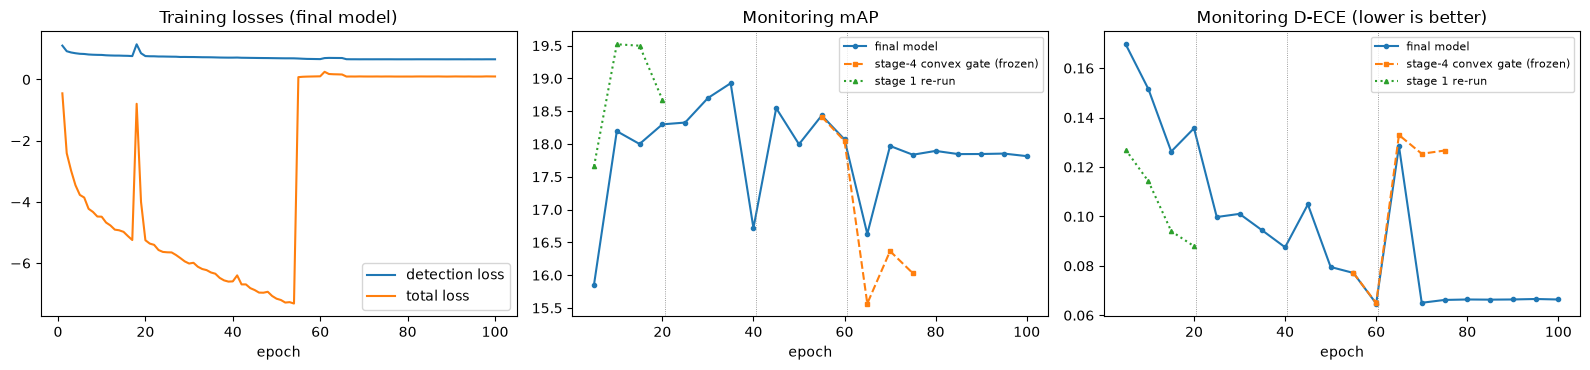

Training time: 13.8 h logged for the final model
stage  epochs logged  mean s/epoch
-----  -------------  ------------
1                 20           334
2                 20           471
3                 20           657
4                 40           515


In [3]:
def load_log(run):
    return [json.loads(l) for l in open(f"checkpoints/{run}/train_log.jsonl")]
prim, resid, frozen, s1 = (load_log(r) for r in ("uavdt_primary", "uavdt_stage4_residual", "uavdt_stage4_frozen", "uavdt_stage1_rerun"))
last = {r["epoch"]: r for r in prim if r["epoch"] < 55}       # resumed epochs appear twice in the log; keep the last row
last.update({r["epoch"]: r for r in resid})
final = [last[e] for e in sorted(last)]
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ep = [r["epoch"] for r in final]
ax[0].plot(ep, [r["loss_det"] for r in final], label="detection loss")
ax[0].plot(ep, [r["loss_total"] for r in final], label="total loss")
ax[0].set_xlabel("epoch"); ax[0].set_title("Training losses (final model)"); ax[0].legend()
for name, rows, st in (("final model", final, "-o"), ("stage-4 convex gate (frozen)", frozen, "--s"), ("stage 1 re-run", s1, ":^")):
    v = [r for r in rows if "val_mAP" in r]
    ax[1].plot([r["epoch"] for r in v], [100 * r["val_mAP"] for r in v], st, ms=3, label=name)
    ax[2].plot([r["epoch"] for r in v], [r["val_D-ECE"] for r in v], st, ms=3, label=name)
for a, title in ((ax[1], "Monitoring mAP"), (ax[2], "Monitoring D-ECE (lower is better)")):
    for e in (20.5, 40.5, 60.5):
        a.axvline(e, color="grey", lw=0.6, ls=":")
    a.set_xlabel("epoch"); a.set_title(title); a.legend(fontsize=8)
plt.tight_layout(); plt.show()
secs = {}
for r in final:
    secs.setdefault(r["stage"], []).append(r["epoch_seconds"])
show_table(["stage", "epochs logged", "mean s/epoch"], [[k, len(v), f"{np.mean(v):.0f}"] for k, v in sorted(secs.items())],
           f"Training time: {sum(sum(v) for v in secs.values()) / 3600:.1f} h logged for the final model")

In [4]:
guard = json.load(open("checkpoints/uavdt_stage4_residual/stage4_guard.json"))
print(f"Stage-4 guard: reference mAP {guard['ref_mAP']:.4f}, rollbacks: {guard['rollbacks']}")
show_table(["epoch", "monitoring mAP", "action"], [[h["epoch"], f"{h['mAP']:.4f}", h["action"]] for h in guard["history"]])

Stage-4 guard: reference mAP 0.1807, rollbacks: 1
epoch  monitoring mAP    action
-----  --------------  --------
65             0.1663  rollback
70             0.1797        ok
75             0.1784        ok
80             0.1789        ok
85             0.1785        ok
90             0.1785        ok
95             0.1785        ok
100            0.1782        ok


## 4. Main result on the 3,318 test frames (Table II)

In [5]:
def metrics(path, key="default"):
    return json.load(open(path))["metrics"][key]
sv = metrics("results/final_model/test_single_view.json")
tta = metrics("results/final_model/test_tta.json", "tuned")
pct = lambda m: [f"{100 * m[k]:.1f}" for k in ("mAP", "AP50", "AP75", "APs", "APm", "APl")]
rows = [["UCR-MFG (single view)"] + pct(sv) + [f"{sv['D-ECE']:.3f}"],
        ["UCR-MFG + TTA"] + pct(tta) + [f"{tta['D-ECE']:.3f}"],
        ["DMNet*", "14.7", "24.6", "16.3", "9.3", "26.2", "35.2", "-"],
        ["GLSAN*", "17.0", "28.1", "18.8", "-", "-", "-", "-"],
        ["AMRNet*", "18.2", "30.4", "19.8", "10.3", "31.3", "33.5", "-"]]
show_table(["method", "mAP", "AP50", "AP75", "APs", "APm", "APl", "D-ECE"], rows,
           "Table II (ours: results/final_model/test_single_view.json and test_tta.json)")
print("\n* published, ResNet-50: 23,258 training and 15,069 test images at 1000x600; not directly comparable; '-': not reported.")

Table II (ours: results/final_model/test_single_view.json and test_tta.json)
method                  mAP  AP50  AP75   APs   APm   APl  D-ECE
---------------------  ----  ----  ----  ----  ----  ----  -----
UCR-MFG (single view)  17.5  32.4  17.4  11.0  29.1  30.1  0.066
UCR-MFG + TTA          18.9  35.0  18.5  11.9  30.0  32.1  0.106
DMNet*                 14.7  24.6  16.3   9.3  26.2  35.2      -
GLSAN*                 17.0  28.1  18.8     -     -     -      -
AMRNet*                18.2  30.4  19.8  10.3  31.3  33.5      -

* published, ResNet-50: 23,258 training and 15,069 test images at 1000x600; not directly comparable; '-': not reported.


## 5. Comparison with the plain detector (Table IV)
The baseline is FCOS + C1 with the same backbone, heads, data and loss, without the graph modules (re-trained stage 1).

In [6]:
base = metrics("results/stages/stage1/test.json")
rows = []
for name, m in (("FCOS + C1 (baseline)", base), ("UCR-MFG (full)", sv)):
    rows.append([name, f"{100*m['mAP']:.1f}", f"{100*m['AP50']:.1f}", f"{m['D-ECE']:.3f}", f"{m['AUROC']['u_a']:.3f}", f"{m['AUROC']['u_e']:.3f}"])
show_table(["model", "mAP", "AP50", "D-ECE", "AUROC Ua", "AUROC Ue"], rows, "Table IV")
print(f"\nmAP change {100*(sv['mAP']-base['mAP']):+.2f} points (exact); D-ECE {100*(sv['D-ECE']/base['D-ECE']-1):+.0f}%; "
      f"AUROC Ua {base['AUROC']['u_a']:.3f} -> {sv['AUROC']['u_a']:.3f}; AUROC Ue {base['AUROC']['u_e']:.3f} -> {sv['AUROC']['u_e']:.3f}")

Table IV
model                  mAP  AP50  D-ECE  AUROC Ua  AUROC Ue
--------------------  ----  ----  -----  --------  --------
FCOS + C1 (baseline)  18.4  33.7  0.088     0.919     0.866
UCR-MFG (full)        17.5  32.4  0.066     0.960     0.931

mAP change -0.84 points (exact); D-ECE -25%; AUROC Ua 0.919 -> 0.960; AUROC Ue 0.866 -> 0.931


In [7]:
stages = [("1: FCOS + C1", "results/stages/stage1/test.json", 20), ("2: + fuzzy graph", "results/stages/stage2/test.json", 35),
          ("3: + C2, C3", "results/stages/stage3/test.json", 60), ("4: + C4 (final)", "results/final_model/test_single_view.json", 100)]
show_table(["model after stage", "epoch", "mAP", "AP50", "D-ECE", "AUROC Ua", "AUROC Ue"],
           [[n, e, f"{100*m['mAP']:.1f}", f"{100*m['AP50']:.1f}", f"{m['D-ECE']:.3f}", f"{m['AUROC']['u_a']:.3f}", f"{m['AUROC']['u_e']:.3f}"]
            for n, p, e in stages for m in [metrics(p)]], "All curriculum stages on the test frames (single view)")

All curriculum stages on the test frames (single view)
model after stage  epoch   mAP  AP50  D-ECE  AUROC Ua  AUROC Ue
-----------------  -----  ----  ----  -----  --------  --------
1: FCOS + C1          20  18.4  33.7  0.088     0.919     0.866
2: + fuzzy graph      35  18.8  35.7  0.094     0.913     0.860
3: + C2, C3           60  18.0  32.9  0.065     0.956     0.922
4: + C4 (final)      100  17.5  32.4  0.066     0.960     0.931


## 6. Breakdown by class, weather and altitude (Table III)

Per class
class  AP single  AP + TTA
-----  ---------  --------
car         32.1      34.2
truck        5.6       6.0
bus         14.9      16.6

Per condition
condition         test frames  mAP single  mAP + TTA
----------------  -----------  ----------  ---------
weather:daylight         1875        16.2       17.5
weather:night            1008        28.4       28.9
weather:fog               435        12.0       14.7
altitude:low             1398        38.5       39.0
altitude:medium          1585        19.1       20.6
altitude:high             335         7.4        9.8


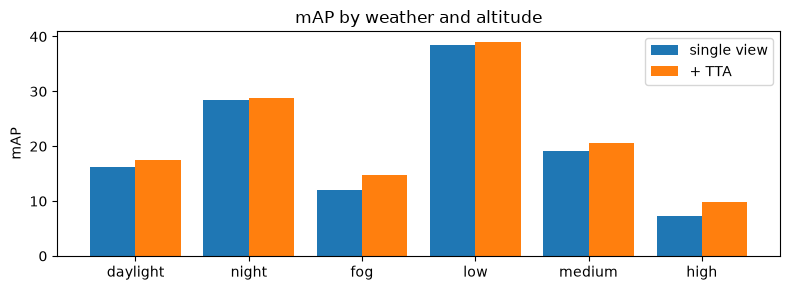

In [8]:
rows = [[c, f"{100*a:.1f}", f"{100*b:.1f}"] for c, a, b in zip(("car", "truck", "bus"), sv["per_class_AP"], tta["per_class_AP"])]
show_table(["class", "AP single", "AP + TTA"], rows, "Per class")
print()
order = ["weather:daylight", "weather:night", "weather:fog", "altitude:low", "altitude:medium", "altitude:high"]
show_table(["condition", "test frames", "mAP single", "mAP + TTA"],
           [[k, sv["conditions"][k]["num_images"], f"{100*sv['conditions'][k]['mAP']:.1f}", f"{100*tta['conditions'][k]['mAP']:.1f}"] for k in order],
           "Per condition")
fig, ax = plt.subplots(figsize=(8, 3))
xs = np.arange(len(order))
ax.bar(xs - 0.2, [100*sv["conditions"][k]["mAP"] for k in order], 0.4, label="single view")
ax.bar(xs + 0.2, [100*tta["conditions"][k]["mAP"] for k in order], 0.4, label="+ TTA")
ax.set_xticks(xs); ax.set_xticklabels([k.split(":")[1] for k in order]); ax.set_ylabel("mAP"); ax.legend()
ax.set_title("mAP by weather and altitude"); plt.tight_layout(); plt.show()

## 7. Uncertainty quality
AUROC with which each score separates false from true detections (higher is better), and calibration error D-ECE.

In [9]:
keys = ["u_a", "u_e", "box_std", "1-score"]
show_table(["score", "single view", "+ TTA"], [[k, f"{sv['AUROC'][k]:.3f}", f"{tta['AUROC'][k]:.3f}"] for k in keys], "Error-detection AUROC")
print(f"\nD-ECE: single view {sv['D-ECE']:.3f}, + TTA {tta['D-ECE']:.3f}")

Error-detection AUROC
score    single view  + TTA
-------  -----------  -----
u_a            0.960  0.945
u_e            0.931  0.917
box_std        0.975  0.663
1-score        0.970  0.967

D-ECE: single view 0.066, + TTA 0.106


## 8. Test-time augmentation: how the setting was chosen
TTA is not trained. Settings were scored on 554 tuning frames (every 30th test frame, disjoint from the 3,318 evaluation frames); the chosen setting is in `results/final_model/stage4_end_choice.json`.

In [10]:
tune = json.load(open("results/final_model/stage4_end_tune.json"))
choice = json.load(open("results/final_model/stage4_end_choice.json"))
def desc(s):
    v = "+".join(f"{x:g}x" for x in s["scales"]) + (" +flip" if s["flip"] else "")
    m = f"NMS {s['nms_iou']}" if s["merge"] == "nms" else f"Matrix-NMS s={s['sigma']}"
    return f"{v}, {m}, thr {s['score_thresh']}"
print(f"{len(tune['rows'])} settings scored on {tune['meta'].get('num_images', 554)} tuning frames; default mAP {tune['default']['mAP']:.4f}")
top = sorted(tune["rows"], key=lambda r: -r["mAP"])[:8]
show_table(["setting", "tuning mAP", "AP50", "cost"], [[desc(r["setting"]), f"{r['mAP']:.4f}", f"{r['AP50']:.4f}", f"{r['cost']:.2f}x"] for r in top],
           "Top settings on the tuning frames")
print(f"\nchosen setting (rule: {choice['tuned_on']['rule']}): {desc(choice['by_fold']['0'])}")
print(f"test result: single view {100*sv['mAP']:.1f} mAP -> with TTA {100*tta['mAP']:.1f} mAP")

64 settings scored on 554 tuning frames; default mAP 0.1822
Top settings on the tuning frames
setting                                     tuning mAP    AP50   cost
------------------------------------------  ----------  ------  -----
1x+1.25x +flip, Matrix-NMS s=2.0, thr 0.02      0.1905  0.3463  5.12x
1x+1.25x +flip, Matrix-NMS s=2.0, thr 0.05      0.1905  0.3463  5.12x
1x+1.25x +flip, NMS 0.6, thr 0.02               0.1892  0.3502  5.12x
1x+1.25x +flip, NMS 0.6, thr 0.05               0.1892  0.3502  5.12x
1x+1.25x +flip, NMS 0.5, thr 0.02               0.1883  0.3519  5.12x
1x+1.25x +flip, NMS 0.5, thr 0.05               0.1883  0.3519  5.12x
1x +flip, Matrix-NMS s=2.0, thr 0.02            0.1877  0.3360  2.00x
1x +flip, Matrix-NMS s=2.0, thr 0.05            0.1877  0.3360  2.00x

chosen setting (rule: robust): 1x+1.25x +flip, NMS 0.6, thr 0.02
test result: single view 17.5 mAP -> with TTA 18.9 mAP


## 9. Sample detections: single view vs TTA (live)
The four frames of the paper figure (daylight dense traffic, night, fog, high altitude), detections with score ≥ 0.3; green car, orange truck, blue bus.

In [11]:
from tune_inference import DEFAULT_SETTING, FIELDS_FULL, load_model, merge, run_views, view_keys_for
from src.engine import LocationCache
from make_qualitative import f1
model, meta = load_model(["models/stage4_ep100_final.pth"], device)
loc = LocationCache(model.det_head)
tta_setting = choice["by_fold"]["0"]
frames = [("Daylight, dense", "M0403", 169), ("Night", "M1001", 202), ("Fog", "M1009", 295), ("High altitude", "M0701", 204)]
by_id = {(s, n): i for i, (s, _, n) in enumerate(test.frames)}
fig, axes = plt.subplots(2, 4, figsize=(18, 5.4))
rows = []
for col, (title, seq, num) in enumerate(frames):
    i = by_id[(seq, num)]; s = test[i]
    for row, (mode, st) in enumerate((("single", DEFAULT_SETTING), ("TTA", tta_setting))):
        with torch.no_grad():
            v = run_views(model, loc, s["image"], st["scales"], st["flip"], device, 0, i, s["ignore_mask"].numpy(), FIELDS_FULL)
        d = merge(v, view_keys_for(st), st, FIELDS_FULL)
        k = (d["scores"] >= 0.3) & ~d["ignored"]
        ax = axes[row, col]; ax.imshow(s["image"].permute(1, 2, 0).numpy())
        for b, l in zip(d["boxes"][k], d["labels"][k]):
            ax.add_patch(plt.Rectangle((b[0], b[1]), b[2]-b[0], b[3]-b[1], fill=False, ec=("#00e676", "#ff9100", "#2979ff")[int(l)], lw=0.6))
        ax.set_xticks([]); ax.set_yticks([])
        if row == 0: ax.set_title(title)
        if col == 0: ax.set_ylabel("UCR-MFG" if row == 0 else "+ TTA")
        rows.append([title, mode, len(s["boxes"]), int(k.sum()), f"{f1(d, s['boxes'].numpy(), 0.3):.2f}"])
plt.tight_layout(); plt.show()
show_table(["condition", "mode", "GT vehicles", "detections >= 0.3", "F1 (IoU 0.5)"], rows)

condition          mode  GT vehicles  detections >= 0.3  F1 (IoU 0.5)
---------------  ------  -----------  -----------------  ------------
Daylight, dense  single           63                 61          0.94
Daylight, dense     TTA           63                 83          0.85
Night            single           22                 22          0.95
Night               TTA           22                 24          0.91
Fog              single           20                 22          0.95
Fog                 TTA           20                 30          0.80
High altitude    single           53                 49          0.96
High altitude       TTA           53                 58          0.95


## 10. Inference speed

In [12]:
from src.models.uncertainty_head import mc_generator
model.eval()
times = []
with torch.no_grad():
    for j, i in enumerate(eval_idx[:25]):
        x = test[i]["image"].unsqueeze(0).to(device)
        t0 = time.time(); o = model(x, generator=mc_generator(0, 0, i, device))
        _ = o["head"]["cls"][0].sum().item()
        if j >= 5: times.append(time.time() - t0)
print(f"forward pass incl. 10 MC-dropout passes: median {np.median(times):.3f} s per image on {device} "
      f"({1/np.median(times):.1f} images/s, {len(times)} frames, batch 1)")

forward pass incl. 10 MC-dropout passes: median 0.258 s per image on mps (3.9 images/s, 20 frames, batch 1)


## 11. Reproduce the test numbers
```bash
# single view and TTA on the 3,318 test frames
python scripts/tune_inference.py test --weights models/stage4_ep100_final.pth \
  --choice results/final_model/stage4_end_choice.json --stride 5 --offset 2
```
The `default` column of the output is the single-view result (17.5 mAP) and the `tuned` column the TTA result (18.9 mAP).